In [4]:
import kagglehub
import pandas as pd
import os

# Download latest version
path = kagglehub.dataset_download("neelagiriaditya/ufc-datasets-1994-2025")

print("Path to dataset files:", path)

c:\Users\ml328\Desktop\MineriaDeDatos\MIDUSI2026 - Público\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\ml328\.cache\kagglehub\datasets\neelagiriaditya\ufc-datasets-1994-2025\versions\3


In [5]:
# Ver los archivos descargados en la ruta
archivos = os.listdir(path)
print("Archivos descargados:", archivos)

# Buscar el archivo .csv y mostrar su head
for archivo in archivos:
    if archivo.endswith('.csv'):
        ruta_csv = os.path.join(path, archivo)
        df = pd.read_csv(ruta_csv)
        display(df.head())
        break

Archivos descargados: ['event_details.csv', 'fighter_details.csv', 'fight_details.csv', 'UFC.csv']


,event_id,fight_id,date,location,winner,winner_id
0,6e380a4d73ab4f0e,5bcd8abf6da01dae,"September 06, 2025","Paris, Ile-de-France, France",Nassourdine Imavov,881bf86d4cba8578
1,6e380a4d73ab4f0e,d14fea43712707f0,"September 06, 2025","Paris, Ile-de-France, France",Benoit Saint Denis,c2299ec916bc7c56
2,6e380a4d73ab4f0e,0149e875b31e57f8,"September 06, 2025","Paris, Ile-de-France, France",Modestas Bukauskas,476fe566d2df676e
3,6e380a4d73ab4f0e,69b31593175f77ec,"September 06, 2025","Paris, Ile-de-France, France",Mason Jones,f6ad6a1e4d600e0d
4,6e380a4d73ab4f0e,a47123ae6e048f11,"September 06, 2025","Paris, Ile-de-France, France",Axel Sola,1d2d98ddd05b38fb


In [6]:
# Cargar específicamente UFC.csv
ruta_ufc = os.path.join(path, 'UFC.csv')
df_ufc = pd.read_csv(ruta_ufc)

# Crear un DataFrame con el tipo de dato y la cantidad de valores nulos por columna
resumen = pd.DataFrame({
    'Tipo de Dato': df_ufc.dtypes,
    'Datos Faltantes': df_ufc.isnull().sum()
})

# Guardar el resumen en un archivo CSV para poder verlo completo
resumen.to_csv('resumen_ufc.csv')
print("Resumen guardado exitosamente en 'resumen_ufc.csv' en el directorio actual.")

display(resumen)

Resumen guardado exitosamente en 'resumen_ufc.csv' en el directorio actual.


,Tipo de Dato,Datos Faltantes
event_id,str,0
event_name,str,0
date,str,0
location,str,0
fight_id,str,0
...,...,...
b_td_avg_acc,int64,0
b_td_def,int64,0
b_sub_avg,float64,0
winner,str,147


# Exploratory Data Analysis

Esta sección analiza el dataset desde cuatro ángulos: contexto del evento, perfil físico de cada peleador, métricas de estilo de pelea y relaciones entre rincón rojo y azul.

La idea es entender qué variables describen mejor cada combate y qué patrones se asocian con el resultado final.

In [7]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 12

# Copia de trabajo
eda = df_ufc.copy()

# Fechas y variables derivadas básicas
for col in ["date", "r_dob", "b_dob"]:
    if col in eda.columns:
        eda[col] = pd.to_datetime(eda[col], errors="coerce")

if "date" in eda.columns:
    eda["year"] = eda["date"].dt.year
    eda["month"] = eda["date"].dt.to_period("M").astype(str)

if {"r_dob", "b_dob", "date"}.issubset(eda.columns):
    eda["r_age"] = (eda["date"] - eda["r_dob"]).dt.days / 365.25
    eda["b_age"] = (eda["date"] - eda["b_dob"]).dt.days / 365.25
    eda["age_diff_rb"] = eda["r_age"] - eda["b_age"]

numeric_cols = eda.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = eda.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print(f"Filas: {eda.shape[0]:,} | Columnas: {eda.shape[1]:,}")
print(f"Numéricas: {len(numeric_cols)} | Categóricas/bool: {len(cat_cols)}")
print("Nulos totales:", int(eda.isna().sum().sum()))

display(
    pd.DataFrame({
        "tipo": eda.dtypes.astype(str),
        "nulos": eda.isna().sum(),
        "pct_nulos": (eda.isna().mean() * 100).round(2)
    }).sort_values("pct_nulos", ascending=False).head(20)
)

Filas: 8,337 | Columnas: 129
Numéricas: 108 | Categóricas/bool: 18
Nulos totales: 31136


C:\Users\ml328\AppData\Local\Temp\ipykernel_11128\196921551.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = eda.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


,tipo,nulos,pct_nulos
b_ground_acc,float64,3816,45.77
b_td_acc,float64,3126,37.50
r_ground_acc,float64,2956,35.46
r_td_acc,float64,2686,32.22
b_nick_name,str,2388,28.64
r_nick_name,str,2328,27.92
b_clinch_acc,float64,2042,24.49
r_clinch_acc,float64,2003,24.03
r_leg_acc,float64,1584,19.00
b_leg_acc,float64,1568,18.81


## Filtrado a peleas masculinas

Primero construimos un dataset solo con peleas masculinas. La división nos permite identificar y excluir las categorías femeninas.


Total peleas: 8,337
Peleas masculinas: 7,471
Peleas femeninas: 866


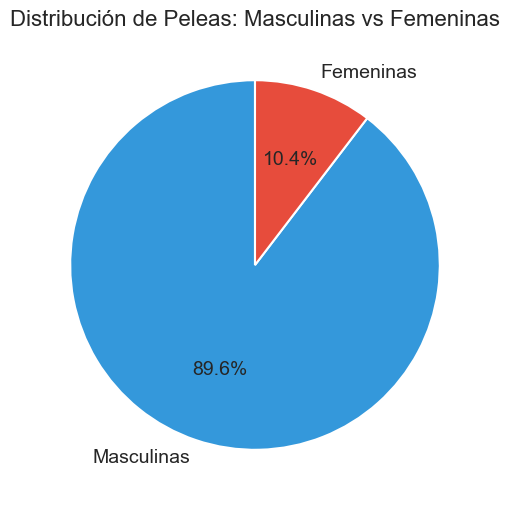

,event_id,event_name,date,location,fight_id,division,title_fight,method,finish_round,match_time_sec,...,b_splm,b_str_acc,b_sapm,b_str_def,b_td_avg,b_td_avg_acc,b_td_def,b_sub_avg,winner,winner_id
0,6e380a4d73ab4f0e,UFC Fight Night: Imavov vs. Borralho,2025/09/06,"Paris, Ile-de-France, France",d14fea43712707f0,lightweight,0,Submission,2,176,...,3.84,57,4.16,60,0.00,0,84,0.0,Benoit Saint Denis,c2299ec916bc7c56
1,6e380a4d73ab4f0e,UFC Fight Night: Imavov vs. Borralho,2025/09/06,"Paris, Ile-de-France, France",5bcd8abf6da01dae,middleweight,0,Decision - Unanimous,5,300,...,3.44,56,2.50,60,1.28,48,76,0.4,Nassourdine Imavov,881bf86d4cba8578
2,6e380a4d73ab4f0e,UFC Fight Night: Imavov vs. Borralho,2025/09/06,"Paris, Ile-de-France, France",0149e875b31e57f8,light heavyweight,0,KO/TKO,1,300,...,2.50,45,3.04,43,1.43,18,35,1.3,Modestas Bukauskas,476fe566d2df676e
3,6e380a4d73ab4f0e,UFC Fight Night: Imavov vs. Borralho,2025/09/06,"Paris, Ile-de-France, France",69b31593175f77ec,lightweight,0,KO/TKO,2,198,...,5.71,41,4.47,50,4.17,55,81,0.2,Mason Jones,f6ad6a1e4d600e0d
4,6e380a4d73ab4f0e,UFC Fight Night: Imavov vs. Borralho,2025/09/06,"Paris, Ile-de-France, France",a47123ae6e048f11,welterweight,0,KO/TKO,3,122,...,4.71,40,7.15,47,0.00,0,47,0.0,Axel Sola,1d2d98ddd05b38fb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8332,a6a9ab5a824e8f66,UFC 2: No Way Out,1994/03/11,"Denver, Colorado, USA",3b020d4914b44fc8,open weight,0,KO/TKO,1,170,...,0.00,0,0.00,0,0.00,0,0,0.0,Orlando Wiet,a6c2f5381d575920
8333,a6a9ab5a824e8f66,UFC 2: No Way Out,1994/03/11,"Denver, Colorado, USA",ccee020be2e8d9f6,open weight,0,KO/TKO,1,733,...,0.00,0,0.00,0,0.00,0,0,0.0,Johnny Rhodes,319fa1bd3176bded
8334,a6a9ab5a824e8f66,UFC 2: No Way Out,1994/03/11,"Denver, Colorado, USA",d917c8c7461b9831,open weight,0,Submission,1,292,...,0.00,0,0.00,0,0.00,0,0,0.0,Frank Hamaker,c3c23c99477c041b
8335,a6a9ab5a824e8f66,UFC 2: No Way Out,1994/03/11,"Denver, Colorado, USA",4b9ae533ccb3fcdf,open weight,0,Submission,1,58,...,0.00,0,0.00,0,0.00,0,0,0.0,Patrick Smith,46c8ec317aff28ac


In [8]:
import matplotlib.pyplot as plt

# Filtrar solo peleas masculinas por division
eda_male = df_ufc.copy()

if "division" in eda_male.columns:
    female_mask = eda_male["division"].astype(str).str.contains("women", case=False, na=False)
    eda_male = eda_male.loc[~female_mask].copy()

total_peleas = len(df_ufc)
peleas_masculinas = len(eda_male)
peleas_femeninas = total_peleas - peleas_masculinas

print(f"Total peleas: {total_peleas:,}")
print(f"Peleas masculinas: {peleas_masculinas:,}")
print(f"Peleas femeninas: {peleas_femeninas:,}")

plt.figure(figsize=(6, 6))
labels = ['Masculinas', 'Femeninas']
sizes = [peleas_masculinas, peleas_femeninas]
colors = ['#3498db', '#e74c3c']

plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90, textprops={'fontsize': 14})
plt.title('Distribución de Peleas: Masculinas vs Femeninas', fontsize=16)
plt.show()

# Usar este dataset como base del EDA
eda = eda_male.copy()
eda

## Diagnóstico general del dataset

Primero revisamos cobertura temporal, faltantes y distribución de las variables categóricas principales.

Tipos de datos actualizados en el dataset 'eda' (Muestra de las primeras 15 columnas):


event_id                     str
event_name                   str
date              datetime64[us]
location                     str
fight_id                     str
division                     str
title_fight                int64
method                       str
finish_round               int64
match_time_sec             int64
total_rounds             float64
referee                      str
r_name                       str
r_id                         str
r_kd                     float64
dtype: object

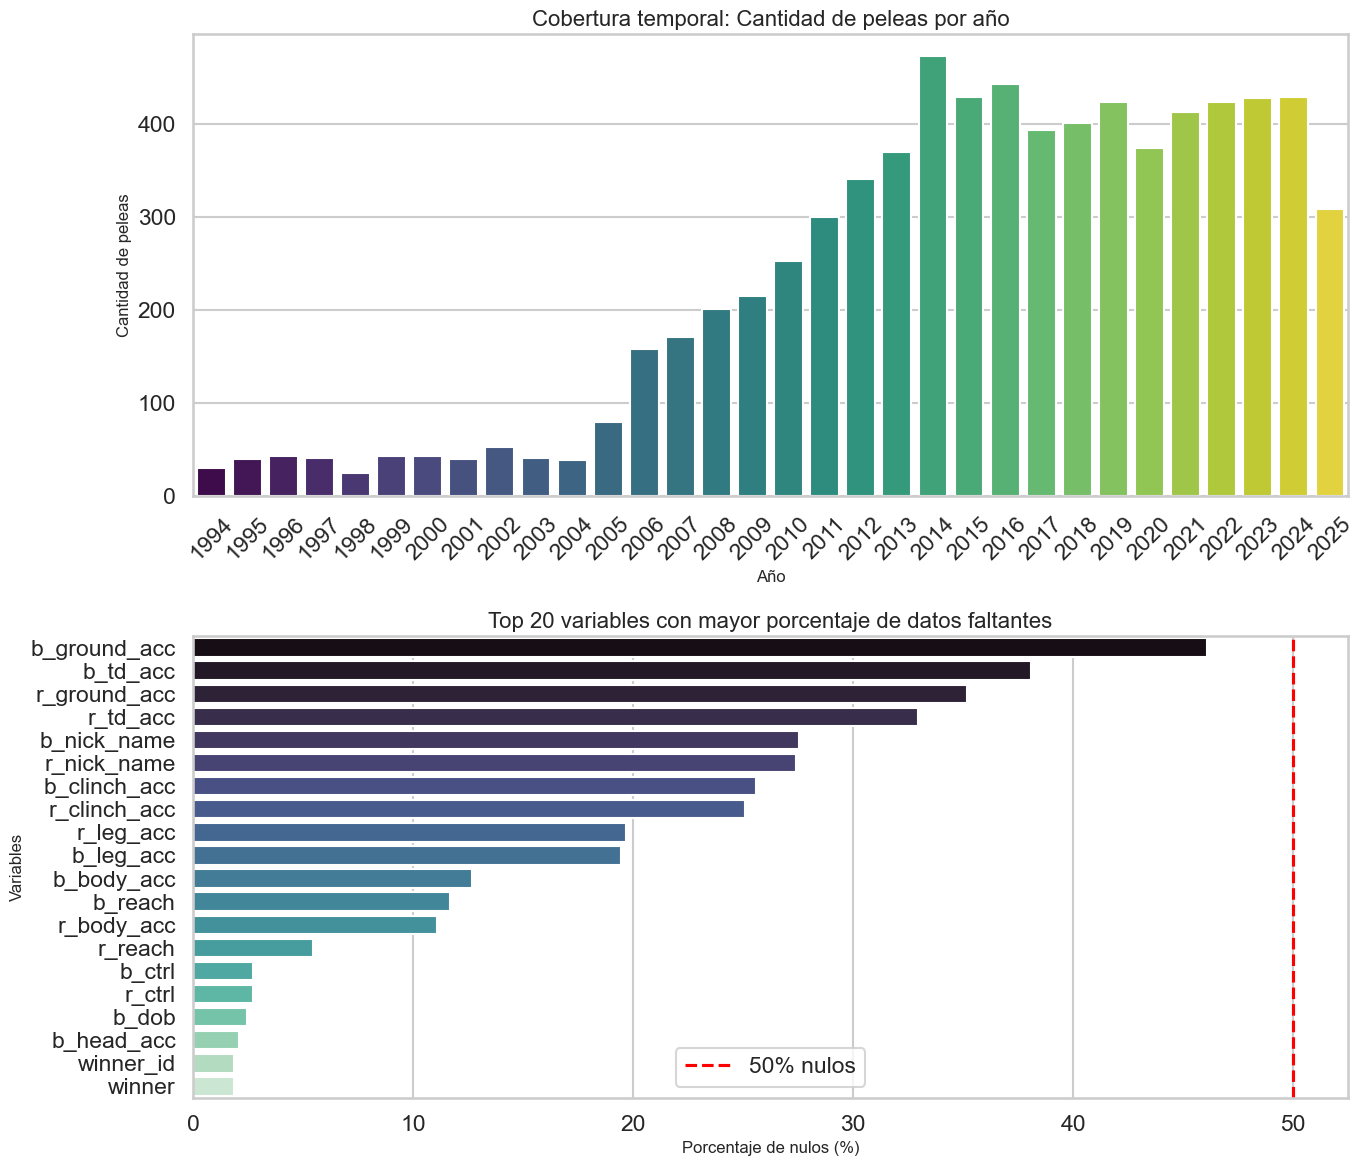

Cantidad de valores únicos en las variables categóricas principales:


C:\Users\ml328\AppData\Local\Temp\ipykernel_11128\589373917.py:45: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_info = eda.select_dtypes(include=['object', 'category']).nunique().sort_values(ascending=False)


fight_id       7471
b_id           2221
b_name         2220
r_id           1717
r_name         1716
winner_id      1632
winner         1631
b_nick_name    1211
r_nick_name    1002
event_id        745
dtype: int64

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Recuperamos las transformaciones de fecha que se perdieron al reasignar 'eda'
for col in ["date", "r_dob", "b_dob"]:
    if col in eda.columns:
        eda[col] = pd.to_datetime(eda[col], errors='coerce')

if 'date' in eda.columns:
    eda['year'] = eda['date'].dt.year
    eda['month'] = eda['date'].dt.to_period("M").astype(str)

# Imprimimos los tipos de dato ya corregidos
print("Tipos de datos actualizados en el dataset 'eda' (Muestra de las primeras 15 columnas):")
display(eda.dtypes.head(15))

fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# 1. Cobertura temporal (Peleas por año)
if 'year' in eda.columns:
    sns.countplot(data=eda, x='year', hue='year', ax=axes[0], palette="viridis", legend=False)
    axes[0].set_title("Cobertura temporal: Cantidad de peleas por año", fontsize=16)
    axes[0].set_xlabel("Año")
    axes[0].set_ylabel("Cantidad de peleas")
    axes[0].tick_params(axis='x', rotation=45)

# 2. Análisis de datos faltantes (Gráfico de atributos con más nulos)
nulos_porcentaje = (eda.isna().mean() * 100).sort_values(ascending=False)
nulos_porcentaje = nulos_porcentaje[nulos_porcentaje > 0] # Solo las columnas que tienen nulos

if not nulos_porcentaje.empty:
    sns.barplot(x=nulos_porcentaje.values[:20], y=nulos_porcentaje.index[:20], hue=nulos_porcentaje.index[:20], ax=axes[1], palette="mako", legend=False)
    axes[1].set_title("Top 20 variables con mayor porcentaje de datos faltantes", fontsize=16)
    axes[1].set_xlabel("Porcentaje de nulos (%)")
    axes[1].set_ylabel("Variables")
    # Línea de referencia en 50%
    axes[1].axvline(50, color='red', linestyle='--', label='50% nulos')
    axes[1].legend()

plt.tight_layout()
plt.show()

# 3. Distribución de variables categóricas
cat_cols_info = eda.select_dtypes(include=['object', 'category']).nunique().sort_values(ascending=False)
print("Cantidad de valores únicos en las variables categóricas principales:")
display(cat_cols_info.head(10))

## Evento y combate

Acá miramos la estructura de cada pelea: división, método de cierre, round de finalización y duración total.

C:\Users\ml328\AppData\Local\Temp\ipykernel_11128\3103212897.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, y="division", order=division_order, ax=axes[0, 0], palette="crest")
C:\Users\ml328\AppData\Local\Temp\ipykernel_11128\3103212897.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, y="method", order=method_order, ax=axes[0, 1], palette="mako")


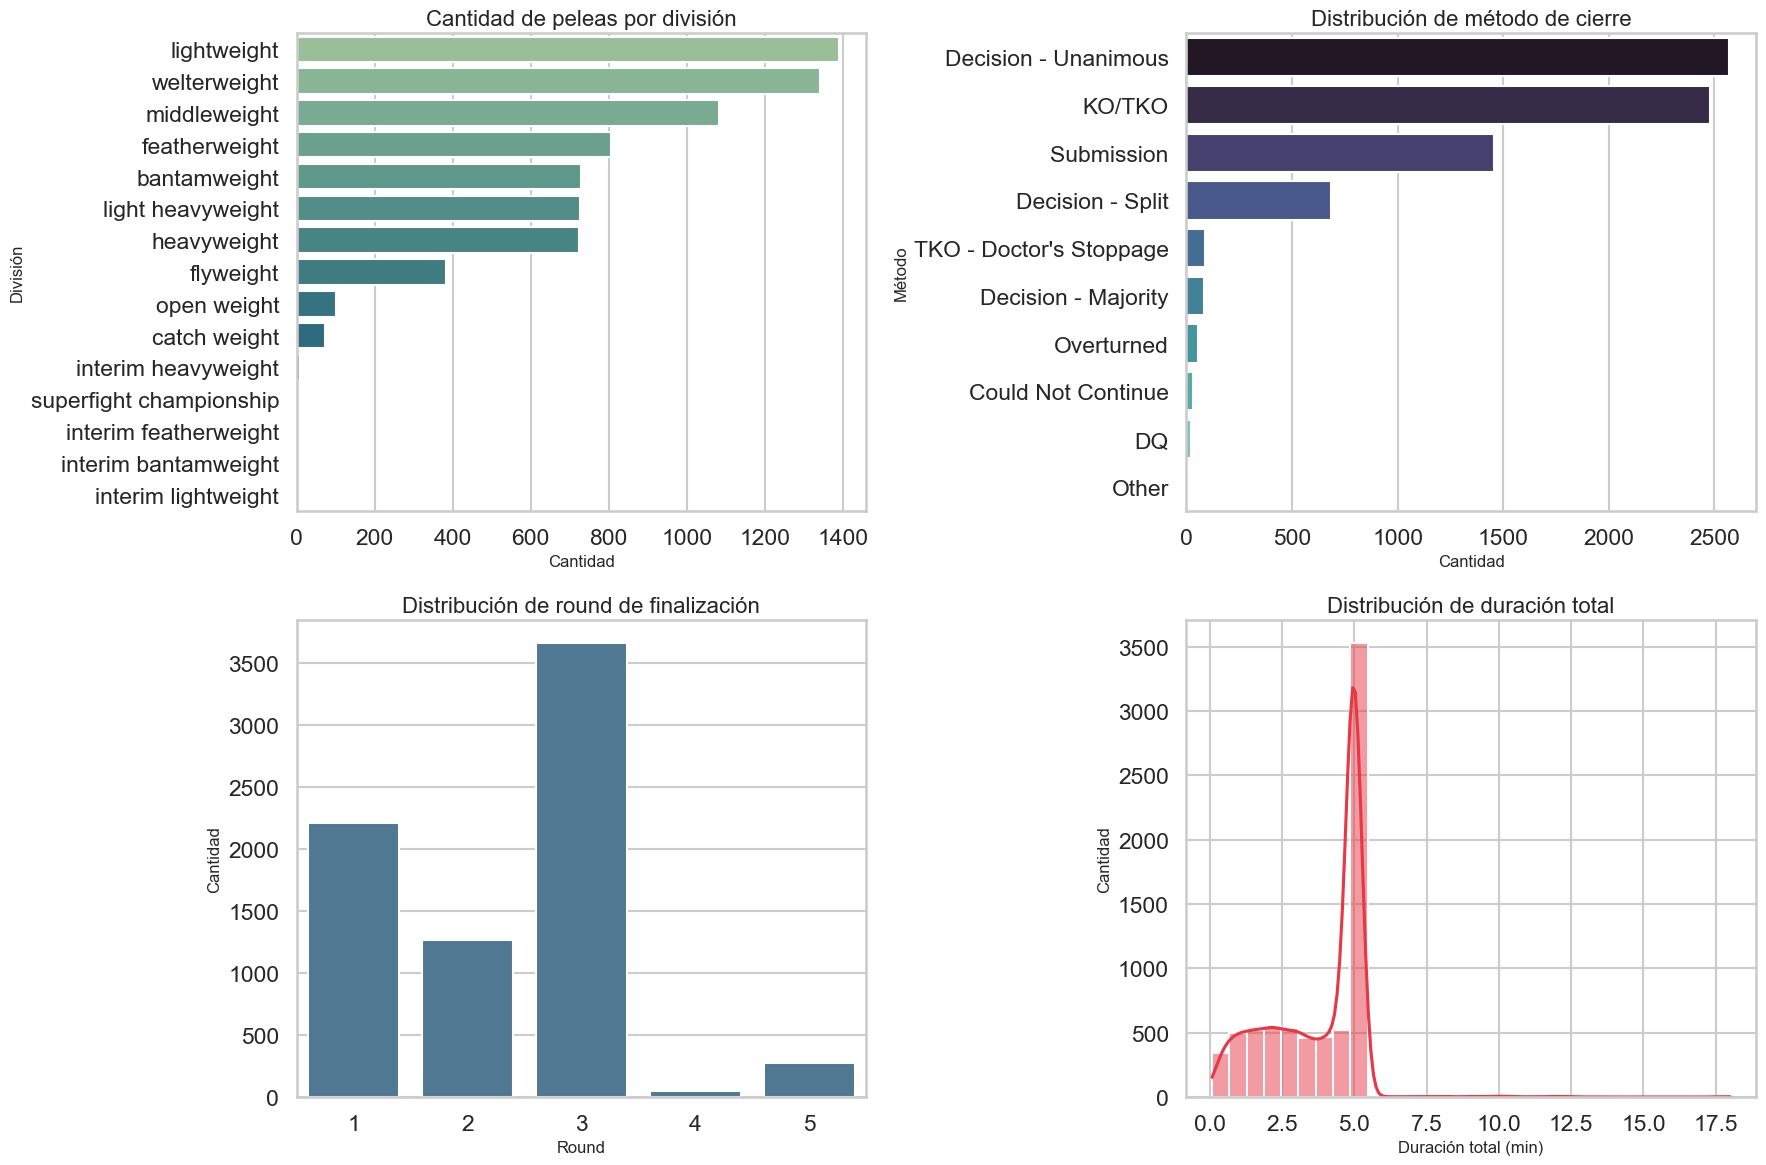

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Usar dataset masculino
data = eda_male.copy()

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1) Cantidad de peleas por division
division_order = data["division"].astype(str).value_counts().index[:15]
sns.countplot(data=data, y="division", order=division_order, ax=axes[0, 0], palette="crest")
axes[0, 0].set_title("Cantidad de peleas por división")
axes[0, 0].set_xlabel("Cantidad")
axes[0, 0].set_ylabel("División")

# 2) Distribucion de metodo de cierre
method_order = data["method"].astype(str).value_counts().index[:15]
sns.countplot(data=data, y="method", order=method_order, ax=axes[0, 1], palette="mako")
axes[0, 1].set_title("Distribución de método de cierre")
axes[0, 1].set_xlabel("Cantidad")
axes[0, 1].set_ylabel("Método")

# 3) Distribucion de round de finalizacion
sns.countplot(data=data, x="finish_round", ax=axes[1, 0], color="#457b9d")
axes[1, 0].set_title("Distribución de round de finalización")
axes[1, 0].set_xlabel("Round")
axes[1, 0].set_ylabel("Cantidad")

# 4) Distribucion de duracion total en minutos
data["match_time_min"] = data["match_time_sec"] / 60
sns.histplot(data=data, x="match_time_min", bins=30, kde=True, ax=axes[1, 1], color="#e63946")
axes[1, 1].set_title("Distribución de duración total")
axes[1, 1].set_xlabel("Duración total (min)")
axes[1, 1].set_ylabel("Cantidad")

plt.tight_layout()
plt.show()

## Perfil físico y biográfico

Aquí se comparan altura, peso, alcance, edad y postura. La meta es ver si el tamaño y la edad ya separan estilos o resultados.

In [11]:
# Partimos de eda_male (1 fila = 1 pelea)
# Primero, nos quedamos solo con las peleas que tienen un ganador claro (donde winner_id no es nulo)
eda_wl = eda_male.dropna(subset=['winner_id']).copy()

# Listamos dinámicamente las columnas que pertenecen a cada esquina
r_cols = [c for c in eda_wl.columns if c.startswith('r_')]
b_cols = [c for c in eda_wl.columns if c.startswith('b_')]

# Separamos el dataset en peleas ganadas por el Rojo y ganadas por el Azul
red_wins = eda_wl[eda_wl['winner_id'] == eda_wl['r_id']].copy()
blue_wins = eda_wl[eda_wl['winner_id'] == eda_wl['b_id']].copy()

# Para las peleas que ganó el Rojo: r_ pasa a ser w_ (winner) y b_ pasa a ser l_ (loser)
rename_red = {c: 'w_' + c[2:] for c in r_cols}
rename_red.update({c: 'l_' + c[2:] for c in b_cols})
red_wins = red_wins.rename(columns=rename_red)

# Para las peleas que ganó el Azul: b_ pasa a ser w_ (winner) y r_ pasa a ser l_ (loser)
rename_blue = {c: 'w_' + c[2:] for c in b_cols}
rename_blue.update({c: 'l_' + c[2:] for c in r_cols})
blue_wins = blue_wins.rename(columns=rename_blue)

# Concatenamos ambos subsets para obtener el nuevo dataset orientado por Winner/Loser
eda_wl = pd.concat([red_wins, blue_wins], ignore_index=True)

# (Opcional) Si tenías columnas calculadas basadas en la esquina (ej. la diferencia de edad),
# la eliminamos o recalculamos basándonos en Winner - Loser
if 'age_diff_rb' in eda_wl.columns:
    eda_wl = eda_wl.drop(columns=['age_diff_rb'])
if 'w_age' in eda_wl.columns and 'l_age' in eda_wl.columns:
    eda_wl['age_diff_wl'] = eda_wl['w_age'] - eda_wl['l_age']

print(f"Dataset original (eda_male): {eda_male.shape}")
print(f"Nuevo dataset orientado a Ganador/Perdedor (eda_wl): {eda_wl.shape}")

# Verificamos rápidamente algunas columnas
w_cols = [c for c in eda_wl.columns if c.startswith('w_')]
print(f"\nSe generaron {len(w_cols)} columnas para el ganador. Ejemplo: {w_cols[:5]}")


Dataset original (eda_male): (7471, 124)
Nuevo dataset orientado a Ganador/Perdedor (eda_wl): (7332, 124)

Se generaron 55 columnas para el ganador. Ejemplo: ['w_name', 'w_id', 'w_kd', 'w_sig_str_landed', 'w_sig_str_atmpted']


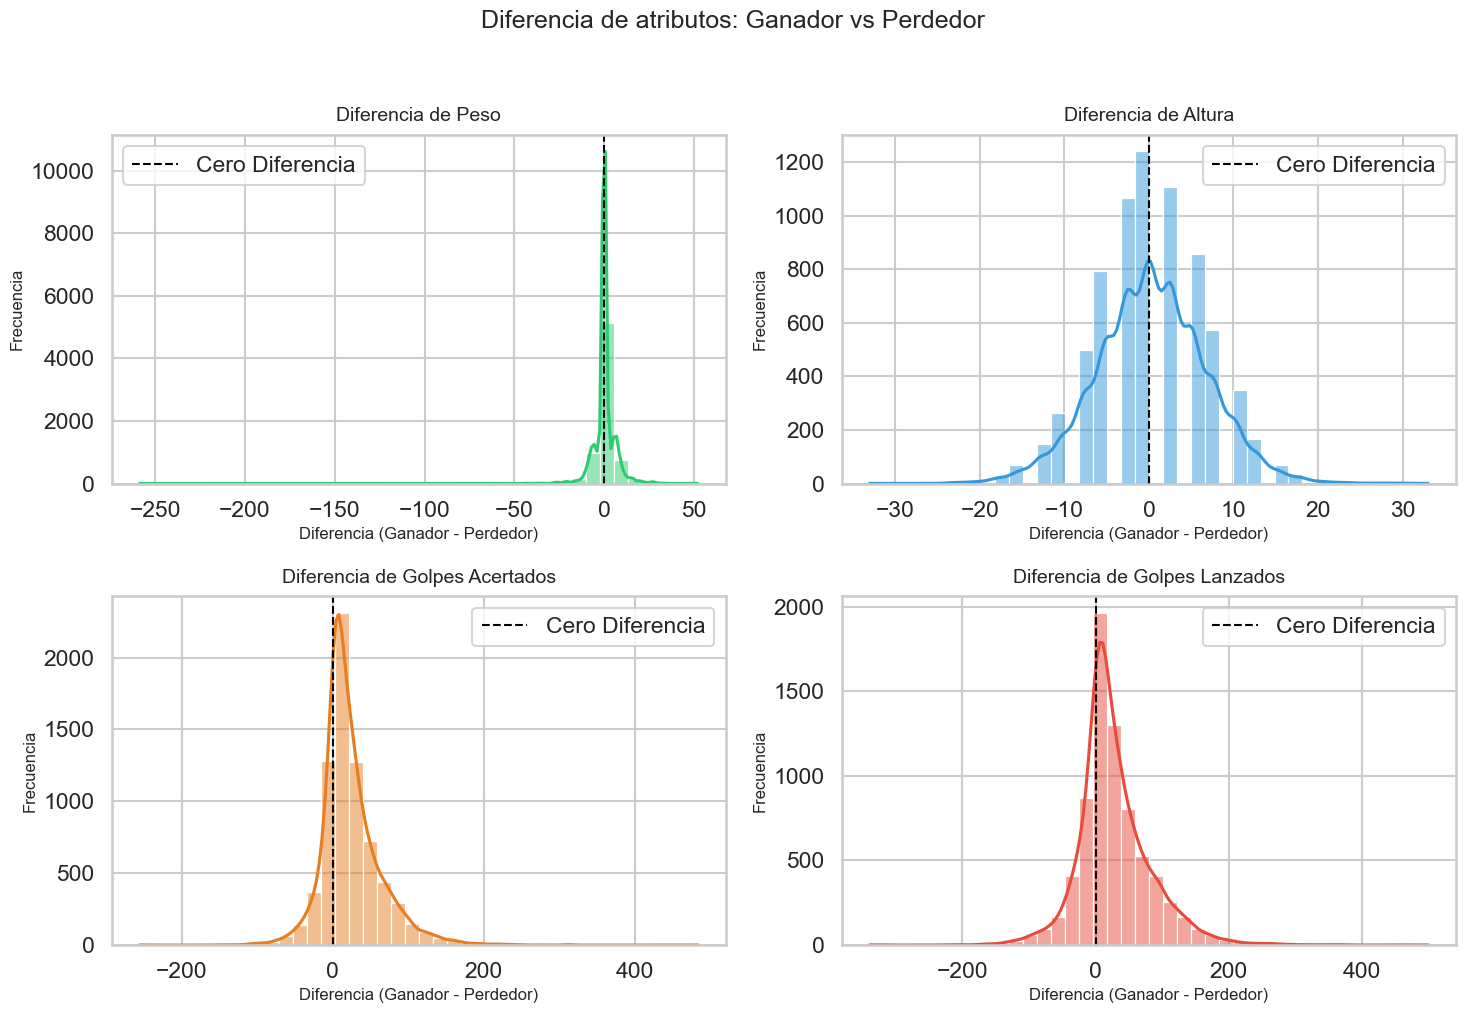

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculamos las diferencias (Ganador - Perdedor)
eda_wl['weight_diff'] = eda_wl['w_weight'] - eda_wl['l_weight']
eda_wl['height_diff'] = eda_wl['w_height'] - eda_wl['l_height']

# Usamos 'total_str' (Golpes totales). Si prefieres golpes significativos, 
# puedes cambiar 'total_str' por 'sig_str' en estas dos líneas.
eda_wl['str_landed_diff'] = eda_wl['w_total_str_landed'] - eda_wl['l_total_str_landed']
eda_wl['str_atmpted_diff'] = eda_wl['w_total_str_atmpted'] - eda_wl['l_total_str_atmpted']

# 2. Configuramos la figura con 4 gráficos (2 filas x 2 columnas)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Diferencia de atributos: Ganador vs Perdedor', fontsize=18, y=1.02)

# Lista de configuración para los gráficos: (Columna, Título, Eje, Color)
graficos = [
    ('weight_diff', 'Diferencia de Peso', axes[0, 0], '#2ecc71'),
    ('height_diff', 'Diferencia de Altura', axes[0, 1], '#3498db'),
    ('str_landed_diff', 'Diferencia de Golpes Acertados', axes[1, 0], '#e67e22'),
    ('str_atmpted_diff', 'Diferencia de Golpes Lanzados', axes[1, 1], '#e74c3c')
]

# 3. Iteramos y generamos cada gráfico
for col, title, ax, color in graficos:
    # Graficamos el histograma con su curva de densidad (KDE)
    sns.histplot(data=eda_wl, x=col, kde=True, ax=ax, color=color, bins=40)
    
    # Línea vertical punteada en 0 (Referencia de "Igualdad")
    # Valores > 0 significan que el Ganador tuvo más. Valores < 0 significan que el Perdedor tuvo más.
    ax.axvline(0, color='black', linestyle='--', linewidth=1.5, label='Cero Diferencia')
    
    ax.set_title(title, fontsize=14, pad=10)
    ax.set_xlabel('Diferencia (Ganador - Perdedor)', fontsize=12)
    ax.set_ylabel('Frecuencia', fontsize=12)
    ax.legend()

plt.tight_layout()
plt.show()


C:\Users\ml328\AppData\Local\Temp\ipykernel_11128\3032210076.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=adv_df, x='Win % con Ventaja', y='Métrica', ax=axes[0], palette="viridis")
C:\Users\ml328\AppData\Local\Temp\ipykernel_11128\3032210076.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


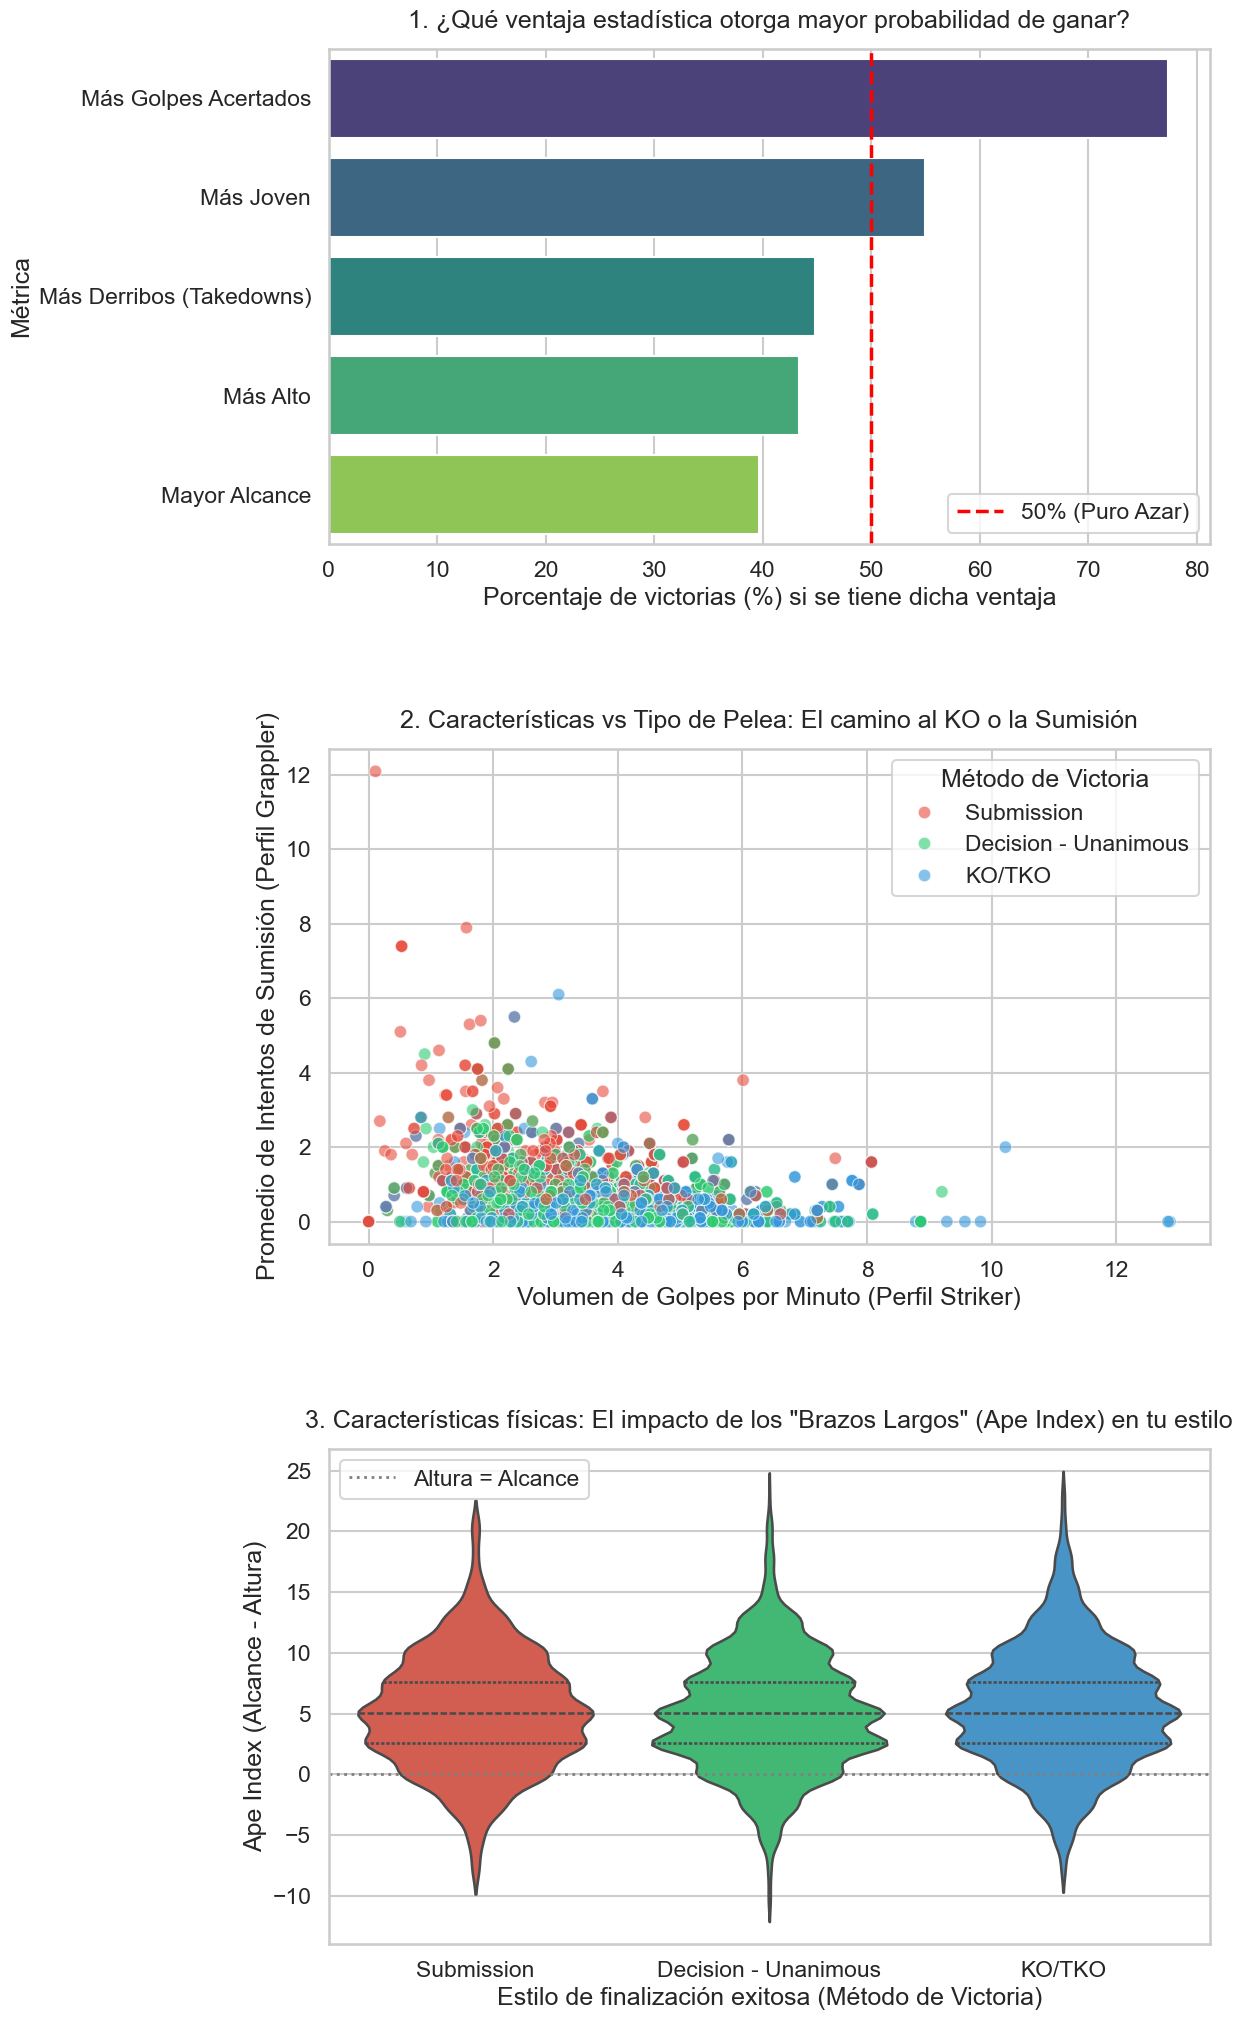

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 0. Preparación de métricas derivadas (Edades y Ape Index)
if 'w_age' not in eda_wl.columns:
    eda_wl['date'] = pd.to_datetime(eda_wl['date'], errors='coerce')
    eda_wl['w_dob'] = pd.to_datetime(eda_wl['w_dob'], errors='coerce')
    eda_wl['w_age'] = (eda_wl['date'] - eda_wl['w_dob']).dt.days / 365.25

if 'l_age' not in eda_wl.columns:
    eda_wl['l_dob'] = pd.to_datetime(eda_wl['l_dob'], errors='coerce')
    eda_wl['l_age'] = (eda_wl['date'] - eda_wl['l_dob']).dt.days / 365.25

# Ape Index = Alcance - Altura
eda_wl['w_ape_index'] = eda_wl['w_reach'] - eda_wl['w_height']

# Filtramos los 3 métodos de victoria más comunes para que los gráficos sean más legibles
main_methods = eda_wl[eda_wl['method'].isin(['KO/TKO', 'Submission', 'Decision - Unanimous'])].copy()

# Configuración general de la figura (3 gráficos apilados verticalmente)
sns.set_theme(style="whitegrid", context="talk")
fig, axes = plt.subplots(3, 1, figsize=(14, 22))

# --- GRÁFICO 1: Probabilidad empírica ---
# Calculamos en qué porcentaje de las peleas, el que tenía la ventaja estadística terminó ganando
adv_stats = {
    'Más Joven': (eda_wl['w_age'] < eda_wl['l_age']).mean() * 100,
    'Más Alto': (eda_wl['w_height'] > eda_wl['l_height']).mean() * 100,
    'Mayor Alcance': (eda_wl['w_reach'] > eda_wl['l_reach']).mean() * 100,
    'Más Golpes Acertados': (eda_wl['w_total_str_landed'] > eda_wl['l_total_str_landed']).mean() * 100,
    'Más Derribos (Takedowns)': (eda_wl['w_td_landed'] > eda_wl['l_td_landed']).mean() * 100
}

adv_df = pd.DataFrame(list(adv_stats.items()), columns=['Métrica', 'Win % con Ventaja'])
adv_df = adv_df.sort_values('Win % con Ventaja', ascending=False)

sns.barplot(data=adv_df, x='Win % con Ventaja', y='Métrica', ax=axes[0], palette="viridis")
axes[0].axvline(50, color='red', linestyle='--', linewidth=2.5, label='50% (Puro Azar)')
axes[0].set_title('1. ¿Qué ventaja estadística otorga mayor probabilidad de ganar?', fontsize=18, pad=15)
axes[0].set_xlabel('Porcentaje de victorias (%) si se tiene dicha ventaja')
axes[0].legend(loc="lower right")

# --- GRÁFICO 2: Perfil del Luchador (Striker vs Grappler) ---
sns.scatterplot(
    data=main_methods, 
    x='w_splm',          # Strikes per minute
    y='w_sub_avg',       # Intentos de sumisión
    hue='method',
    alpha=0.6,
    ax=axes[1],
    palette=['#e74c3c', '#2ecc71', '#3498db']
)
axes[1].set_title('2. Características vs Tipo de Pelea: El camino al KO o la Sumisión', fontsize=18, pad=15)
axes[1].set_xlabel('Volumen de Golpes por Minuto (Perfil Striker)')
axes[1].set_ylabel('Promedio de Intentos de Sumisión (Perfil Grappler)')
axes[1].legend(title='Método de Victoria')

# --- GRÁFICO 3: Biotipo y Estilo ---
# Usamos un Violin Plot para ver la densidad del Ape Index y cómo afecta a la vía de victoria
sns.violinplot(
    data=main_methods, 
    x='method', 
    y='w_ape_index', 
    ax=axes[2],
    palette=['#e74c3c', '#2ecc71', '#3498db'],
    inner="quartile"
)
axes[2].axhline(0, color='gray', linestyle=':', linewidth=2, label='Altura = Alcance')
axes[2].set_title('3. Características físicas: El impacto de los "Brazos Largos" (Ape Index) en tu estilo', fontsize=18, pad=15)
axes[2].set_xlabel('Estilo de finalización exitosa (Método de Victoria)')
axes[2].set_ylabel('Ape Index (Alcance - Altura)')
axes[2].legend()

plt.tight_layout(pad=4.0)
plt.show()


## Estilo y desempeño

Estas celdas miran producción ofensiva, defensa, derribos y sumisiones. Acá se ve el perfil de pelea, no solo el resultado.

## Ventaja relativa y resultado

Aquí construimos diferencias rojo menos azul en variables clave para ver qué señales separan victorias, derrotas y empates.

## Evolución Temporal de la UFC

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 1. Preparación base
# -----------------------------
male_divisions = [
    'flyweight',
    'bantamweight',
    'featherweight',
    'lightweight',
    'welterweight',
    'middleweight',
    'light heavyweight',
    'heavyweight',
    'catch weight',
    'open weight'
]

df_male = df_ufc[df_ufc['division'].isin(male_divisions)].copy()

print(df.shape)
print(df_male.shape)
print(df_male['division'].value_counts())

df_evo = df_male.copy()

df_evo['date'] = pd.to_datetime(df_evo['date'], errors='coerce')
df_evo = df_evo.dropna(subset=['date'])

df_evo['year'] = df_evo['date'].dt.year
df_evo['duration_min'] = df_evo['match_time_sec'] / 60

# Agrupamos métodos para evitar demasiadas categorías
def simplify_method(method):
    if pd.isna(method):
        return 'Other'
    method = str(method)
    if 'KO/TKO' in method or 'TKO' in method:
        return 'KO/TKO'
    elif 'Submission' in method:
        return 'Submission'
    elif 'Decision' in method:
        return 'Decision'
    else:
        return 'Other'

df_evo['method_group'] = df_evo['method'].apply(simplify_method)

# Métricas técnicas promedio entre Red y Blue
df_evo['avg_splm'] = df_evo[['r_splm', 'b_splm']].mean(axis=1)
df_evo['avg_sapm'] = df_evo[['r_sapm', 'b_sapm']].mean(axis=1)
df_evo['avg_str_acc'] = df_evo[['r_str_acc', 'b_str_acc']].mean(axis=1)
df_evo['avg_str_def'] = df_evo[['r_str_def', 'b_str_def']].mean(axis=1)
df_evo['avg_td_avg'] = df_evo[['r_td_avg', 'b_td_avg']].mean(axis=1)
df_evo['avg_sub_avg'] = df_evo[['r_sub_avg', 'b_sub_avg']].mean(axis=1)

# Para evitar ruido de años con muy pocas peleas
fights_per_year = df_evo.groupby('year').size()
valid_years = fights_per_year[fights_per_year >= 20].index
df_evo = df_evo[df_evo['year'].isin(valid_years)]

(8337, 6)
(7358, 124)
division
lightweight          1391
welterweight         1341
middleweight         1082
featherweight         807
bantamweight          729
light heavyweight     726
heavyweight           725
flyweight             383
open weight           101
catch weight           73
Name: count, dtype: int64


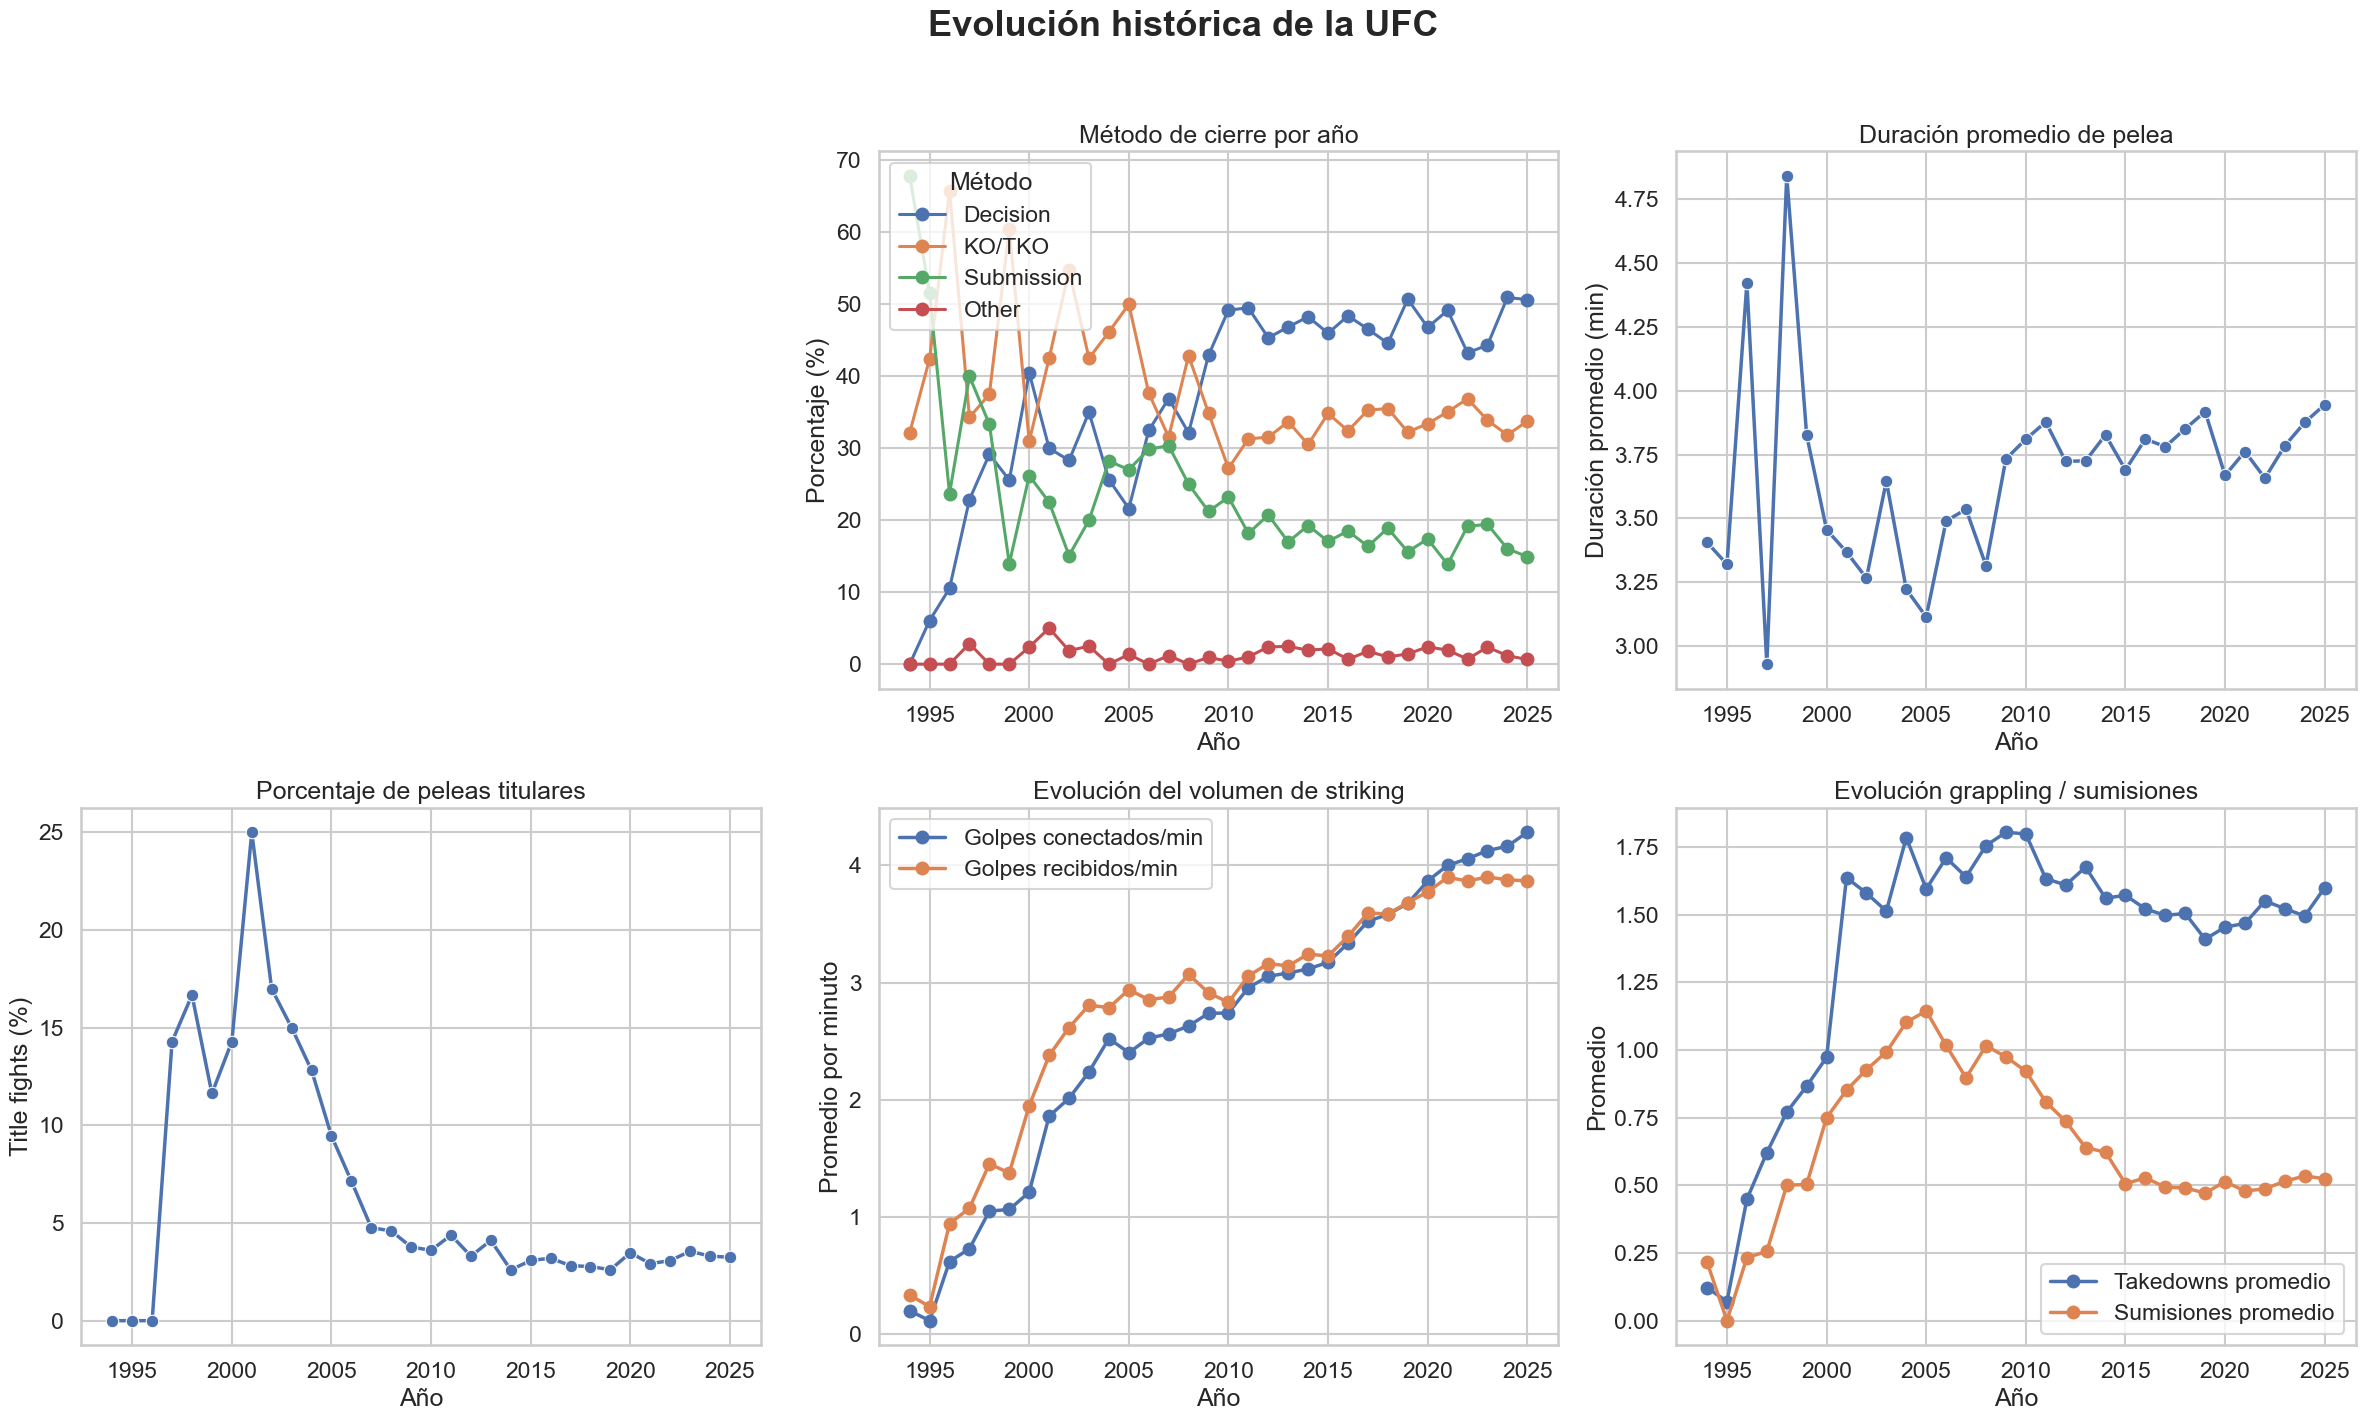

In [ ]:
sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
fig.suptitle("Evolución de finalización y duración de las peleas", fontsize=22, fontweight="bold")

# -----------------------------
# Métodos de cierre
# -----------------------------

method_year = (
    df_evo
    .groupby(['year', 'method_group'])
    .size()
    .reset_index(name='count')
)

method_pivot = method_year.pivot(
    index='year',
    columns='method_group',
    values='count'
).fillna(0)

method_pct = method_pivot.div(method_pivot.sum(axis=1), axis=0) * 100

method_cols = [col for col in ['Decision', 'KO/TKO', 'Submission', 'Other'] if col in method_pct.columns]

for col in method_cols:
    axes[0].plot(
        method_pct.index,
        method_pct[col],
        marker='o',
        linewidth=2.2,
        label=col
    )

axes[0].set_title("Método de cierre por año")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Porcentaje (%)")
axes[0].legend(title="Método")

# -----------------------------
# Duración promedio
# -----------------------------

duration_year = (
    df_evo
    .groupby('year')['duration_min']
    .mean()
    .reset_index()
)

sns.lineplot(
    data=duration_year,
    x='year',
    y='duration_min',
    marker='o',
    linewidth=2.5,
    ax=axes[1]
)

axes[1].set_title("Duración promedio de pelea")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Duración promedio (min)")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("Evolucion_Metodos_Duracion.png", dpi=300, bbox_inches='tight')
plt.show()
sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(1, 3, figsize=(24, 7))
fig.suptitle("Evolución competitiva y técnica de la UFC", fontsize=22, fontweight="bold")

# -----------------------------
# Title fights
# -----------------------------

title_year = (
    df_evo
    .groupby('year')['title_fight']
    .mean()
    .mul(100)
    .reset_index(name='title_fight_pct')
)

sns.lineplot(
    data=title_year,
    x='year',
    y='title_fight_pct',
    marker='o',
    linewidth=2.5,
    ax=axes[0]
)

axes[0].set_title("Porcentaje de peleas titulares")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Title fights (%)")

# -----------------------------
# Striking
# -----------------------------

tech_striking_year = (
    df_evo
    .groupby('year')[['avg_splm', 'avg_sapm']]
    .mean()
    .reset_index()
)

axes[1].plot(
    tech_striking_year['year'],
    tech_striking_year['avg_splm'],
    marker='o',
    linewidth=2.5,
    label='Golpes conectados/min'
)

axes[1].plot(
    tech_striking_year['year'],
    tech_striking_year['avg_sapm'],
    marker='o',
    linewidth=2.5,
    label='Golpes recibidos/min'
)

axes[1].set_title("Evolución del volumen de striking")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Promedio por minuto")
axes[1].legend()

# -----------------------------
# Grappling
# -----------------------------

tech_grappling_year = (
    df_evo
    .groupby('year')[['avg_td_avg', 'avg_sub_avg']]
    .mean()
    .reset_index()
)

axes[2].plot(
    tech_grappling_year['year'],
    tech_grappling_year['avg_td_avg'],
    marker='o',
    linewidth=2.5,
    label='Takedowns promedio'
)

axes[2].plot(
    tech_grappling_year['year'],
    tech_grappling_year['avg_sub_avg'],
    marker='o',
    linewidth=2.5,
    label='Sumisiones promedio'
)

axes[2].set_title("Evolución grappling / sumisiones")
axes[2].set_xlabel("Año")
axes[2].set_ylabel("Promedio")
axes[2].legend()

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("Evolucion_Tecnica.png", dpi=300, bbox_inches='tight')
plt.show()


Se puede observar que la UFC no solo aumentó su volumen de peleas con el tiempo, sino que también parece haberse vuelto un deporte más estable, profesionalizado y estratégico. A medida que avanzan los años, se observa una mayor acumulación de peleas por temporada, una tendencia a combates más largos y una mayor presencia relativa de decisiones frente a finalizaciones tempranas. Esto sugiere que los peleadores modernos llegan mejor preparados, con defensas más desarrolladas y con una capacidad superior para neutralizar amenazas de KO o sumisión.

## Matriz de Correlación Técnica

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 1. Crear dataset en formato long
# -----------------------------

red_cols = {
    'r_splm': 'splm',
    'r_str_acc': 'str_acc',
    'r_sapm': 'sapm',
    'r_str_def': 'str_def',
    'r_td_avg': 'td_avg',
    'r_td_avg_acc': 'td_acc',
    'r_td_def': 'td_def',
    'r_sub_avg': 'sub_avg'
}

blue_cols = {
    'b_splm': 'splm',
    'b_str_acc': 'str_acc',
    'b_sapm': 'sapm',
    'b_str_def': 'str_def',
    'b_td_avg': 'td_avg',
    'b_td_avg_acc': 'td_acc',
    'b_td_def': 'td_def',
    'b_sub_avg': 'sub_avg'
}

red_df = df_male[list(red_cols.keys())].rename(columns=red_cols)
red_df['corner'] = 'Red'

blue_df = df_male[list(blue_cols.keys())].rename(columns=blue_cols)
blue_df['corner'] = 'Blue'

fighters_long = pd.concat([red_df, blue_df], ignore_index=True)

# Limpiar valores faltantes
fighters_long = fighters_long.dropna()

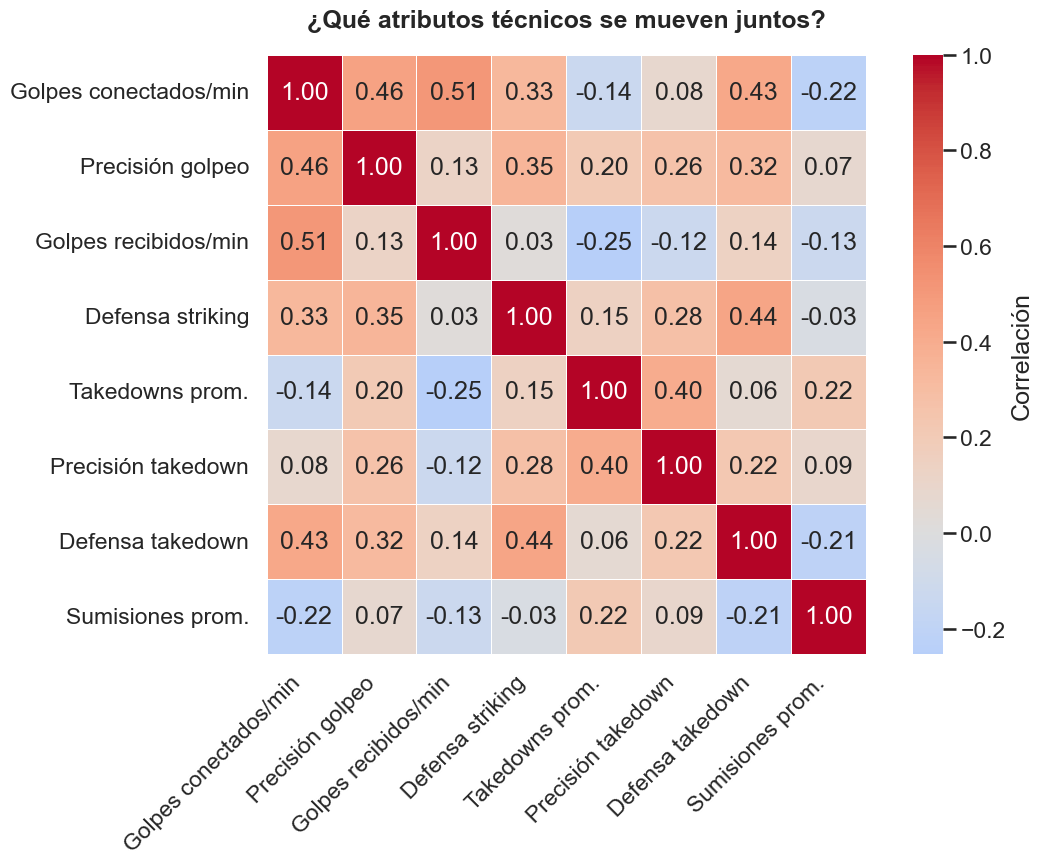

In [17]:
# -----------------------------
# 2. Matriz de correlación
# -----------------------------

technical_cols = [
    'splm',       # golpes conectados por minuto
    'str_acc',    # precisión de golpeo
    'sapm',       # golpes absorbidos por minuto
    'str_def',    # defensa de golpeo
    'td_avg',     # takedowns promedio
    'td_acc',     # precisión de takedown
    'td_def',     # defensa de takedown
    'sub_avg'     # intentos de sumisión promedio
]

corr_matrix = fighters_long[technical_cols].corr()

labels_es = {
    'splm': 'Golpes conectados/min',
    'str_acc': 'Precisión golpeo',
    'sapm': 'Golpes recibidos/min',
    'str_def': 'Defensa striking',
    'td_avg': 'Takedowns prom.',
    'td_acc': 'Precisión takedown',
    'td_def': 'Defensa takedown',
    'sub_avg': 'Sumisiones prom.'
}

corr_matrix_es = corr_matrix.rename(index=labels_es, columns=labels_es)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix_es,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlación"}
)

plt.title("¿Qué atributos técnicos se mueven juntos?", fontsize=18, fontweight="bold", pad=20)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Esta matriz se interpreta de la siguiente manera: La correlación va de -1 a 1. Si en una unión el valor está cerca de 1, entonces suben juntos los atributos. Cerca de -1, uno sube cuando el otro baja. Cerca de 0	no hay relación lineal clara. 
Esto nos permite observar qué dimensiones técnicas tienden a moverse juntas dentro del dataset. En particular, permite distinguir si los perfiles ofensivos de striking se asocian con mayor exposición defensiva, si las métricas de grappling aparecen agrupadas entre sí y si las defensas técnicas —striking defense y takedown defense— se comportan como dimensiones independientes. Esta visualización no prueba causalidad, pero permite detectar patrones estructurales útiles para análisis posteriores de estilos de pelea y predicción de resultados.